# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [16]:
# # change directory to Google Drive for Google Colab
# try:
#     from google.colab import drive
#     import os

#     drive.mount('/content/drive')
#     os.chdir('/content/drive/My Drive/Colab Notebooks/')
#     print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
# except ImportError:
#     pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Bonus by Tung Thien: State space size:__ $|S|=n^n$

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

* __Bonus by Tung Thien: Neighborhood:__ The collection of all new neighboring states that can be reached from the current state by performing exactly one legal move. 

* __Bonus by Tung Thien: Size of neighbors per state:__ $|N(s)|=n(n-1)$

| Size | State Space | Neighbors per state |
|---|---:|---:|
| n = 4 | 256 | 12 |
| n = 8 | 16.777.216 | 56 |

## Helper functions

__Bonus by Tung Thien__: The three function (`random_board()`, `conflicts()`, `show_board()`) work smoothly, for now it does not have any error:

* __`random_board(n)`:__ Generate random board. `n`: Number of queens on the board.

* __`conflicts(board)`:__ Counting the number of queens attacking each other on the current state.

* __`show_board(board)`:__ Show the chess board using Matplotlib.

In [17]:
from helper import random_board, conflicts, show_board, create_experiment_id, save_log_result, summarize_experiment
import numpy as np
from pathlib import Path

## Create a board

Board with 4 conflicts.


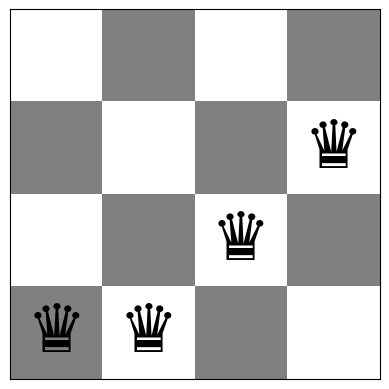

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [18]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


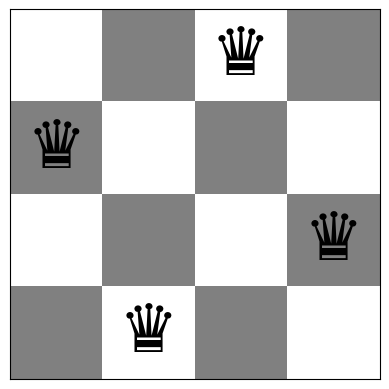

In [19]:
board = [1,3,0,2]
show_board(board)

Board with 8 conflicts.


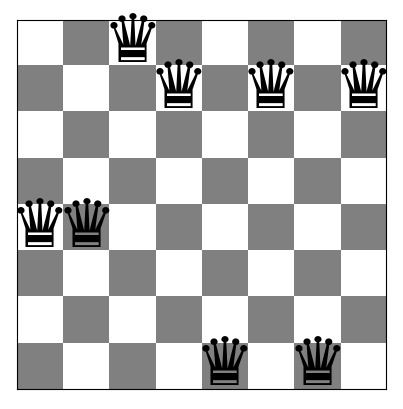

Queens (left to right) are at rows: [4 4 0 1 7 1 7 1]
Number of conflicts: 8


In [20]:
board = random_board(8)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

In [21]:
# Code and description go here

import time

def steepest_ascent_hill_climbing(n, initial_board=None):
    """Steepest-ascent Hill Climbing for n-Queens."""

    start_time = time.perf_counter()

    # Initialize the board
    if initial_board is None:
        board = random_board(n)
    else:
        board = np.array(initial_board, dtype=int).copy()

    current_score = int(conflicts(board))
    evaluations = 1
    iterations = 0
    history = [current_score]

    while current_score > 0:
        best_score = current_score
        best_board = None

        # Evaluate all n*(n-1) local moves
        for col in range(n):
            for row in range(n):
                if row == board[col]:
                    continue

                neighbor = board.copy()
                neighbor[col] = row

                score = int(conflicts(neighbor))
                evaluations += 1

                if score < best_score:
                    best_score = score
                    best_board = neighbor

        # Stop at a local optimum
        if best_board is None:
            break

        board = best_board
        current_score = best_score
        iterations += 1
        history.append(current_score)

    return {
        "board": board,
        "conflicts": current_score,
        "iterations": iterations,
        "evaluations": evaluations,
        "time_ms": (time.perf_counter() - start_time) * 1000,
        "history": history
    }


# Test with n=4 and n=8
for n in [4, 8]:
    result = steepest_ascent_hill_climbing(n)

    print(f"\nBoard size: {n}")
    print(f"Final board: {result['board']}")
    print(f"Conflicts: {result['conflicts']}")
    print(f"Iterations: {result['iterations']}")
    print(f"Evaluations: {result['evaluations']}")
    print(f"Time (ms): {result['time_ms']:.3f}")
    print(f"History: {result['history']}")



Board size: 4
Final board: [2 0 3 1]
Conflicts: 0
Iterations: 2
Evaluations: 25
Time (ms): 0.180
History: [5, 2, 0]

Board size: 8
Final board: [1 7 2 6 3 0 0 4]
Conflicts: 1
Iterations: 3
Evaluations: 225
Time (ms): 1.296
History: [9, 5, 3, 1]


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [22]:
# Code and description go here

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [23]:
# Code and description go here

import time

def efficient_stochastic_hill_climbing(
    n, initial_board=None, max_no_improve=None
):
    """
    Efficient Stochastic (First-choice) Hill Climbing.
    Generate one random neighbor at a time and accept
    it immediately if the number of conflicts decreases.
    """
    if n < 1:
        raise ValueError("n must be positive")

    start = time.perf_counter()

    # Initialize board
    if initial_board is None:
        board = random_board(n)
    else:
        board = np.array(initial_board, dtype=int).copy()

    if len(board) != n or np.any(board < 0) or np.any(board >= n):
        raise ValueError("Invalid initial board")

    current_score = int(conflicts(board))
    evaluations = 1
    iterations = 0
    history = [current_score]

    # Number of possible local moves: n * (n - 1)
    neighbor_count = n * (n - 1)

    # Stop after too many consecutive failed attempts
    if max_no_improve is None:
        max_no_improve = max(1, 5 * neighbor_count)

    if max_no_improve < 1:
        raise ValueError("max_no_improve must be positive")

    failures = 0

    while current_score > 0 and failures < max_no_improve:

        # Select a random column
        col = np.random.randint(n)

        # Select a different row in the same column
        row = np.random.randint(n - 1)
        if row >= board[col]:
            row += 1

        # Generate one random neighbor
        neighbor = board.copy()
        neighbor[col] = row

        # Evaluate the neighbor
        new_score = int(conflicts(neighbor))
        evaluations += 1

        # Accept immediately if the neighbor is better
        if new_score < current_score:
            board = neighbor
            current_score = new_score
            iterations += 1
            history.append(current_score)

            # Reset consecutive failed attempts
            failures = 0
        else:
            failures += 1

    elapsed_ms = (time.perf_counter() - start) * 1000

    return {
        "board": board,
        "conflicts": current_score,
        "iterations": iterations,
        "evaluations": evaluations,
        "time_ms": elapsed_ms,
        "history": history,
        "stopped_reason": (
            "solution" if current_score == 0
            else "no_improvement_limit"
        )
    }


# Experiments with n = 4 and n = 8
for n in [4, 8]:
    np.random.seed(1234)

    result = efficient_stochastic_hill_climbing(n)

    print(f"\nBoard size: {n}")
    print(f"Final board: {result['board']}")
    print(f"Conflicts: {result['conflicts']}")
    print(f"Iterations: {result['iterations']}")
    print(f"Evaluations: {result['evaluations']}")
    print(f"Time (ms): {result['time_ms']:.3f}")
    print(f"History: {result['history']}")
    print(f"Stopped reason: {result['stopped_reason']}")



Board size: 4
Final board: [1 3 0 2]
Conflicts: 0
Iterations: 3
Evaluations: 26
Time (ms): 0.297
History: [4, 3, 1, 0]
Stopped reason: solution

Board size: 8
Final board: [1 3 5 7 4 6 0 2]
Conflicts: 1
Iterations: 6
Evaluations: 331
Time (ms): 3.285
History: [9, 6, 5, 4, 3, 2, 1]
Stopped reason: no_improvement_limit


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [24]:
# Code and description go here

import time

def random_restart_hill_climbing(
    algorithm, n, max_restarts=100
):
    """
    Random Restart Hill Climbing.

    Run a Hill Climbing algorithm from different
    random boards until a solution is found or
    the restart limit is reached.
    """
    if n < 1:
        raise ValueError("n must be positive")

    if max_restarts < 0:
        raise ValueError("max_restarts must be >= 0")

    start_time = time.perf_counter()

    best_result = None
    total_iterations = 0
    total_evaluations = 0
    restart_history = []

    # One initial run + at most max_restarts restarts
    for attempt in range(max_restarts + 1):

        # Generate a new random board
        initial_board = random_board(n)

        # Run the selected Hill Climbing algorithm
        result = algorithm(
            n, initial_board=initial_board
        )

        # Accumulate evaluation metrics
        total_iterations += result["iterations"]
        total_evaluations += result["evaluations"]

        # Keep the best solution across all runs
        if (
            best_result is None
            or result["conflicts"] < best_result["conflicts"]
        ):
            best_result = {
                **result,
                "board": result["board"].copy(),
                "history": result["history"].copy()
            }

        restart_history.append(
            best_result["conflicts"]
        )

        # Stop early when a valid solution is found
        if best_result["conflicts"] == 0:
            break

    elapsed_ms = (
        time.perf_counter() - start_time
    ) * 1000

    return {
        "board": best_result["board"],
        "conflicts": best_result["conflicts"],
        "iterations": total_iterations,
        "evaluations": total_evaluations,
        "time_ms": elapsed_ms,
        "history": best_result["history"],
        "restart_history": restart_history,
        "restarts": attempt,
        "runs": attempt + 1,
        "success": best_result["conflicts"] == 0
    }


# Test Task 4 with Task 1 and Task 3
algorithms = {
    "Steepest-ascent": steepest_ascent_hill_climbing,
    "Efficient Stochastic": efficient_stochastic_hill_climbing
}

for name, algorithm in algorithms.items():
    for n in [4, 8]:

        # Fixed seed for reproducible experiments
        np.random.seed(1234)

        result = random_restart_hill_climbing(
            algorithm, n, max_restarts=100
        )

        print(f"\nAlgorithm: {name}")
        print(f"Board size: {n}")
        print(f"Best board: {result['board']}")
        print(f"Conflicts: {result['conflicts']}")
        print(f"Runs: {result['runs']}")
        print(f"Restarts: {result['restarts']}")
        print(f"Iterations: {result['iterations']}")
        print(f"Evaluations: {result['evaluations']}")
        print(f"Time (ms): {result['time_ms']:.3f}")
        print(f"Success: {result['success']}")
        print(f"Restart history: {result['restart_history']}")



Algorithm: Steepest-ascent
Board size: 4
Best board: [2 0 3 1]
Conflicts: 0
Runs: 2
Restarts: 1
Iterations: 3
Evaluations: 50
Time (ms): 0.275
Success: True
Restart history: [1, 0]

Algorithm: Steepest-ascent
Board size: 8
Best board: [0 4 7 5 2 6 1 3]
Conflicts: 0
Runs: 5
Restarts: 4
Iterations: 15
Evaluations: 1069
Time (ms): 6.229
Success: True
Restart history: [2, 1, 1, 1, 0]

Algorithm: Efficient Stochastic
Board size: 4
Best board: [1 3 0 2]
Conflicts: 0
Runs: 1
Restarts: 0
Iterations: 3
Evaluations: 26
Time (ms): 0.283
Success: True
Restart history: [0]

Algorithm: Efficient Stochastic
Board size: 8
Best board: [6 1 3 0 7 4 2 5]
Conflicts: 0
Runs: 4
Restarts: 3
Iterations: 24
Evaluations: 1115
Time (ms): 11.102
Success: True
Restart history: [1, 1, 1, 0]


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [25]:
from simulated_annealing import simulated_annealing

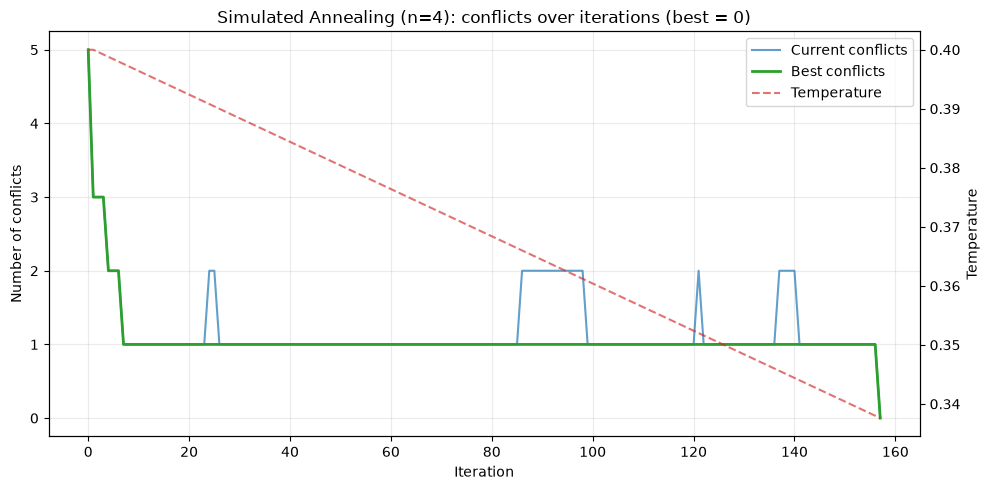

{'experiment_id': 'task5_SA_single_20261013_141558_954470',
 'run_id': 'Simulated_Annealing_n4_run001_20261013_141558_957308',
 'run_number': 1,
 'board_size': 4,
 'best_board': [2, 0, 3, 1],
 'best_conflicts': 0,
 'iterations': 157,
 'history': '158 records',
 'runtime_ms': 2.4626059748698026,
 'seed': 1234,
 'success': True}

History CSV: logs/task5_SA_single_20261013_141558_954470/histories/Simulated_Annealing_n4/Simulated_Annealing_n4_run001_20261013_141558_957308.csv
Runs CSV: logs/task5_SA_single_20261013_141558_954470/runs.csv
Summary CSV: logs/task5_SA_single_20261013_141558_954470/summary.csv
Biểu đồ run: img/task_5_SA/task5_SA_single_20261013_141558_954470/runs/Simulated_Annealing_n4_run001_20261013_141558_957308.png


In [11]:
single_experiment_id = create_experiment_id("task5_SA_single")

single_n4_result = simulated_annealing(n=4)
single_n4_log = save_log_result(
    single_n4_result,
    algorithm="Simulated Annealing",
    experiment_id=single_experiment_id,
    run_number=1,
    plot_run=True,
    show_plot=True,
)

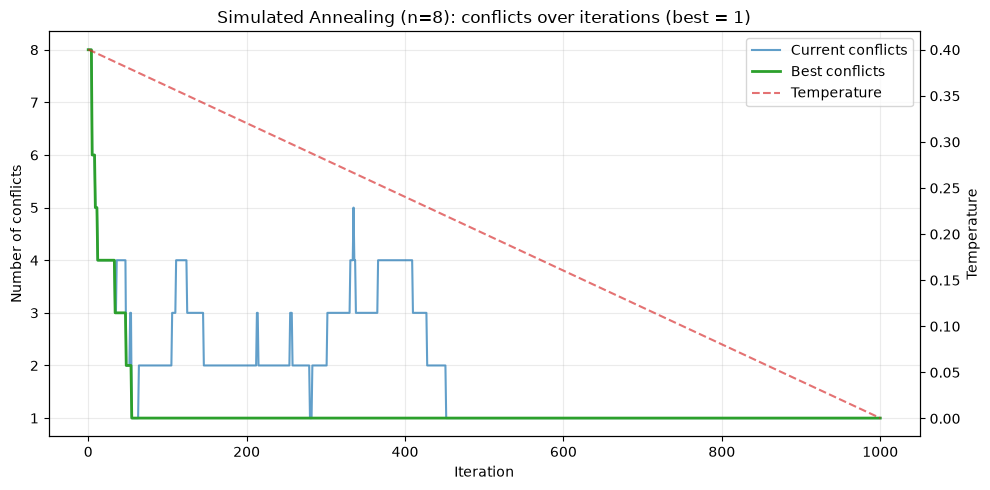

{'experiment_id': 'task5_SA_single_20261013_141558_954470',
 'run_id': 'Simulated_Annealing_n8_run001_20261013_141559_347957',
 'run_number': 1,
 'board_size': 8,
 'best_board': [2, 7, 5, 1, 4, 6, 0, 3],
 'best_conflicts': 1,
 'iterations': 1000,
 'history': '1001 records',
 'runtime_ms': 10.357115010265261,
 'seed': 1234,
 'success': False}

History CSV: logs/task5_SA_single_20261013_141558_954470/histories/Simulated_Annealing_n8/Simulated_Annealing_n8_run001_20261013_141559_347957.csv
Runs CSV: logs/task5_SA_single_20261013_141558_954470/runs.csv
Summary CSV: logs/task5_SA_single_20261013_141558_954470/summary.csv
Biểu đồ run: img/task_5_SA/task5_SA_single_20261013_141558_954470/runs/Simulated_Annealing_n8_run001_20261013_141559_347957.png


In [12]:
single_n8_result = simulated_annealing(n=8)
single_n8_log = save_log_result(
    single_n8_result,
    algorithm="Simulated Annealing",
    experiment_id=single_experiment_id,
    run_number=1,
    plot_run=True,
    show_plot=True,
)

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [26]:

"""Code này chạy thực nghiệm thuật toán SA 100 lần cho 2 trường hợp: bảng 4 quân hậu và bảng 8 quân hậu"""
SA_RUNS_PER_SIZE = 100
sa_batch_experiment_id = create_experiment_id("task6_SA_100_runs")
# Không reset seed trong loop: RANDOM_SEED=1234 sinh một chuỗi board khác nhau,
# nhưng toàn bộ experiment vẫn tái lập được khi Run All.

for board_size in (4, 8):
    # Tạo đúng 100 starting board khác nhau cho mỗi kích thước.
    unique_starting_boards = []
    seen_boards = set()

    while len(unique_starting_boards) < SA_RUNS_PER_SIZE:
        candidate = tuple(np.random.randint(0, board_size, size=board_size))
        if candidate not in seen_boards:
            seen_boards.add(candidate)
            unique_starting_boards.append(np.asarray(candidate, dtype=int))

    for run_number, starting_board in enumerate(
        unique_starting_boards, start=1
    ):
        run_result = simulated_annealing(
            n=board_size,
            board=starting_board,
        )

        save_log_result(
            run_result,
            algorithm="Simulated Annealing",
            experiment_id=sa_batch_experiment_id,
            run_number=run_number,
            plot_run=False,
            show_plot=False,
            verbose=False,
        )

# Chỉ hiển thị kết quả tổng hợp sau khi hoàn tất 100 run cho mỗi board size.
sa_summary = summarize_experiment(
    sa_batch_experiment_id,
    show_plot=False,
    verbose=False,
)

print(
    "Summary CSV:",
    Path("logs") / sa_batch_experiment_id / "summary.csv",
)
sa_summary

Summary CSV: logs/task6_SA_100_runs_20261013_141559_716365/summary.csv


,algorithm,board_size,runs,avg_runtime_ms,avg_conflicts,avg_iterations,optimal_solution_rate_pct
0,Simulated Annealing,4,100,0.3495,0.00,38.30,100.0
1,Simulated Annealing,8,100,4.4715,0.17,463.11,83.0


### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

In [27]:
# Code and description go here

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

In [28]:
# Code and description go here

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [29]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [30]:
# Code and description go here